# 03 Parasitics and tolerance Monte Carlo (tier P)

[![Open In Colab](https://colab.research.google.com/assets/colab/badge.svg)](https://colab.research.google.com/github/<owner>/dlnn-paper/blob/main/notebooks/03_parasitics_montecarlo.ipynb)

**What this notebook does.** It runs the **P tier** (`dlnn.tiers.parasitics`, documented in `docs/parasitics_model.md`) through its notebook API:

| step | call | what it gives |
|---|---|---|
| the board's delay line | `build_line` | tap FIRs of tile 1, line 0 (Q = 10 and Q = 30 inductors) |
| nominal parts | `run_nominal` | accuracy at Q10 / Q30, board "as designed" (finding F1: no gain trim) |
| tolerances | `mc_study` | Monte Carlo over inductor, capacitor, resistor, gain, clock, V_BE tolerances (50 trials here) |
| sensitivity | `sweep` | one axis at a time |
| article slider data | `make_grid` | a small 3^5 grid over five axes in the `dlnn-sweeps-grid/1` schema |

**At about 1 MHz this is not RF**: the board is a lumped-element circuit, there is no transmission-line physics and no EM solve; scikit-rf is only an ABCD cascade engine. **This simulates a board that is designed, not built; nothing here is a measurement.**

*Lite vs full.* The numbers in the article come from a long batch run (1000 boards, 800-example subset, 5^5 grid: about 10 minutes on a fast box, `python -m dlnn.tiers.parasitics`). Here the lite settings (50 trials, 200-example subset, 3^5 grid, about a minute) are written to `docs/artifacts/data/p_tier/` and **compared** with the stored full run within sampling tolerance; the full-run files (`sweeps_grid.json`, `p_tier.json`) are only regenerated when you set `DLNN_FULL=1`.

In [1]:
# Colab only: install the system tools, clone the repo, install the pinned Python requirements. Skipped everywhere else.
import sys
if 'google.colab' in sys.modules:
    import os, subprocess
    REPO_URL = "https://github.com/<owner>/dlnn-paper"      # TODO: replace with the real URL once the repo is public
    subprocess.run("apt-get -qq install -y ngspice iverilog", shell=True, check=True)
    if not os.path.isdir("/content/dlnn-paper"):
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "/content/dlnn-paper"], check=True)
    os.chdir("/content/dlnn-paper")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

In [2]:
import os, sys, time, json
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists() and (p / "dlnn").is_dir())
os.chdir(ROOT); sys.path.insert(0, str(ROOT))          # run from the repo root so relative paths in the library resolve
import numpy as np
from dlnn import paper
from dlnn.paper import DATA, EXPECTED, WORK
T0 = time.time()
ENV = paper.banner("03 Parasitics and Monte Carlo (tier P)")

03 Parasitics and Monte Carlo (tier P)
  python: 3.12.3
  numpy: 2.5.4
  platform: Linux-6.18.44-fc-v233-x86_64-with-glibc2.39
  ngspice: ngspice-42 : Circuit level simulation program
  iverilog: Icarus Verilog version 12.0 (stable) ()
  node: v22.23.4
  colab: False
  Simulation of a design that is not built. Nothing here is a measurement.


In [3]:
from dlnn.data import modrec
from dlnn.model.npz import load_model
from dlnn.tiers import parasitics as P, virtual
MODEL = "models/tdlnet_b_w8_aware2_fro_ternary.npz"          # the board's default model (board-aware trained, float readout)
ds = modrec.dataset()
FULL = os.environ.get("DLNN_FULL") == "1"
OUT = DATA / "p_tier"; OUT.mkdir(parents=True, exist_ok=True)
EV = DATA / "evidence" / "out" / "P2-M2b"
REFS = paper.read_json(EV / "summary_all.json")["models"]["tdlnet_b_w8_aware2_fro"]       # stored full run (1000 boards, 800-example subset)
REFP = paper.read_json(EV / "tdlnet_b_w8_aware2_fro" / "tiers" / "P.json")
print("model sha256", paper.sha256_file(MODEL)[:16], "| stored full run", REFS["model_file_sha256"][:16])
assert paper.sha256_file(MODEL) == REFS["model_file_sha256"]
rows = []

model sha256 3405923d2c64bb0c | stored full run 3405923d2c64bb0c


## 1. The delay line, `build_line`

Tap FIRs at symbol rate of tile 1, line 0: input RC, buffers, the 56-section LC ladder with parasitic capacitance and Rp, zero-order hold. The symbol period T is calibrated from the pulse-response centroids of taps 0 and 7 (the definition the board-aware models were trained on: 0.889 us here vs 0.890 us in `models/board_aware/line_fir_m1a.json`).

Q10: T = 0.8895 us, sampling phase t0 = 1.050 us, FIR (8, 12)
Q30: T = 0.8901 us, sampling phase t0 = 1.095 us, FIR (8, 12)


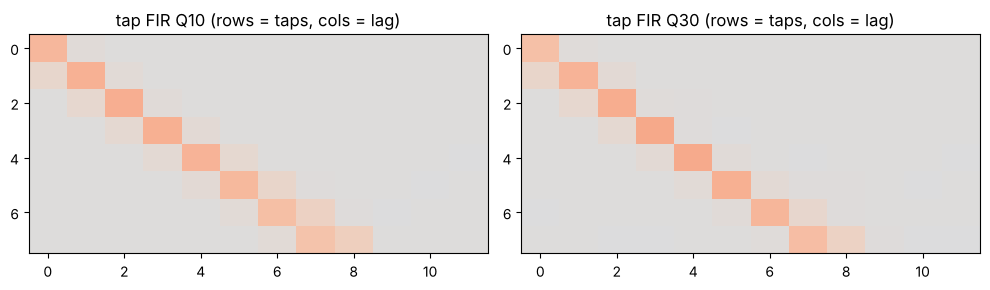

In [4]:
import matplotlib.pyplot as plt
lines = {c: P.build_line(corner=c) for c in ("Q10", "Q30")}
m1a = paper.read_json("models/board_aware/line_fir_m1a.json")["corners"]
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for c, ln in lines.items():
    print(f"{c}: T = {ln['T_us']:.4f} us, sampling phase t0 = {ln['t0_us']:.3f} us, FIR {np.shape(ln['fir'])}")
    ax[0 if c == "Q10" else 1].imshow(ln["fir"], aspect="auto", cmap="coolwarm", vmin=-1, vmax=1)
    ax[0 if c == "Q10" else 1].set_title(f"tap FIR {c} (rows = taps, cols = lag)"); 
    nrm = lambda F: np.asarray(F) / np.mean([abs(np.asarray(F)[k, k]) for k in range(8)])      # the M1a FIR is normalised to unit mean on-lag gain; the gain trim of tier P does that too
    diff = np.abs(nrm(ln["fir"]) - nrm(m1a[c]["fir"])).max()
    paper.check(rows, f"build_line {c}: max |normalised FIR - ngspice M1a FIR|", diff, 0.0, 0.2, note="analytic ABCD (this tier) vs ngspice .ac FIR (M1a)")
    paper.check(rows, f"build_line {c}: T_us", ln["T_us"], 0.8895, 0.01, "us")
fig.tight_layout()

## 2. Nominal parts, `run_nominal`

Full 4000-example test set. `V on the M1a FIR` is the right reference for a board-aware model (ideal V does not include the line's ISI and dispersion); `as designed` is finding F1: with the schematic's resistor values the summer is 6 dB under-driven and the 3-layer cascade collapses.

In [5]:
t = time.time()
nom = P.run_nominal(MODEL, ds, None, OUT)
print(f"run_nominal: {time.time() - t:.1f} s")
for k in ("Q10", "Q30", "Q10_as_designed_trim0dB", "Q10_ideal_wire_no_xtalk"):
    paper.check(rows, f"nominal {k}: accuracy", nom[k]["accuracy"], REFS["nominal"][k]["accuracy"], 0.002, "fraction")
paper.check(rows, "V ideal accuracy (4000)", nom["v_accuracy"], REFS["nominal"]["v_accuracy"], 0.0005, "fraction")
print({k: round(nom[k]["accuracy"], 4) for k in ("Q10", "Q30", "Q10_as_designed_trim0dB", "Q10_ideal_wire_no_xtalk")}, "V ideal", nom["v_accuracy"])

run_nominal: 6.9 s
{'Q10': 0.8705, 'Q30': 0.8722, 'Q10_as_designed_trim0dB': 0.1675, 'Q10_ideal_wire_no_xtalk': 0.8702} V ideal 0.655


## 3. Monte Carlo, sweeps and the slider grid

`export_web` runs `mc_study` (50 trials on a fixed stratified 200-example subset), four `sweep`s and `make_grid` (3 points per axis, 3^5 = 243 points) and writes `p_web.json` + `sweeps_grid.json`. Subset noise at 200 examples is about 2.5 points, so comparisons with the 800-example full run use a 3 to 4 point tolerance.

In [6]:
t = time.time()
web = P.export_web(OUT, MODEL, ds, n_trials=50, mc_subset=200, grid_subset=200, grid_points=3, run_id="notebook-03")
t_web = time.time() - t
print(f"export_web: {t_web:.0f} s ->", sorted(p.name for p in OUT.iterdir()))
mc, mc_ref = web["monte_carlo"], REFS["monte_carlo"]
print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in mc.items()})
paper.check(rows, "Monte Carlo mean accuracy (50 trials, 200-ex subset)", mc["accuracy_mean"], mc_ref["accuracy_mean"], 0.025, "fraction", note="full run: 1000 trials, 800-ex subset")
paper.check(rows, "Monte Carlo sigma", mc["accuracy_std"], mc_ref["accuracy_std"], 0.01, "fraction")
paper.check(rows, "Monte Carlo yield (acc >= V - 5 pt)", mc["yield"], mc_ref["yield"], 0.05, "fraction")

export_web: 53 s -> ['mc.json', 'nominal.json', 'p_web.json', 'sweep_clock_err_pct.json', 'sweep_crosstalk_k.json', 'sweep_l_tol_pct.json', 'sweep_stage_snr_db.json', 'sweeps_grid.json']
{'n_trials': 50, 'accuracy_mean': 0.8509, 'accuracy_std': 0.0075, 'accuracy_p5': 0.84, 'accuracy_min': 0.835, 'accuracy_max': 0.87, 'yield_threshold': 0.595, 'yield': 1.0, 'v_accuracy_same_subset': 0.645, 'agreement_mean': 0.6645, 'runtime_s': 11.8208, 'n_examples': 200, 'seed0': 1000}


True

In [7]:
ref_sw = {s["axis"]: s for s in REFP["sweeps"]}
fig, ax = plt.subplots(1, 4, figsize=(13, 2.8))
for a, name in zip(ax, ("l_tol_pct", "clock_err_pct", "stage_snr_db", "crosstalk_k")):
    s, r = web["sweeps"][name], ref_sw[name]
    a.plot(range(len(s["values"])), s["accuracy"], "o-", label="this notebook (200 ex)")
    a.plot(range(len(r["values"])), r["accuracy"], "s--", alpha=.6, label="stored (1000 ex)")
    a.set_xticks(range(len(s["values"])), [f"{v:g}" for v in s["values"]], fontsize=6); a.set_title(name, fontsize=9); a.set_ylim(0.7, 0.92)
    # same axis points on both sides -> compare point by point
    n = min(len(s["accuracy"]), len(r["accuracy"]))
    paper.check(rows, f"sweep {name}: max |accuracy - stored|", np.abs(np.array(s["accuracy"][:n]) - np.array(r["accuracy"][:n])).max(), 0.0, 0.05, "fraction", note="200 vs 1000 examples")
ax[0].legend(fontsize=6); fig.tight_layout()

In [8]:
g = paper.read_json(OUT / "sweeps_grid.json")
gm = g["models"]["model"] if "model" in g["models"] else next(iter(g["models"].values()))
full = paper.read_json(DATA / "sweeps_grid.json")["models"]["tdlnet_b_w8_aware2_fro"]
a_small = np.array(gm["accuracy"]).reshape(gm["shape"])
a_full = np.array(full["accuracy"]).reshape(full["shape"])
sel = [0, 2, 4]                                   # the 3 points per axis are the first, middle, last of the stored 5
a_sub = a_full[np.ix_(sel, sel, sel, sel, sel)]
assert [a["name"] for a in gm["axes"]] == [a["name"] for a in full["axes"]] and a_small.shape == a_sub.shape
d = np.abs(a_small - a_sub)
print(f"grid {a_small.shape}: mean |small - stored| = {d.mean():.4f}, max = {d.max():.4f}; accuracy range small {a_small.min():.3f}-{a_small.max():.3f}, stored {a_full.min():.3f}-{a_full.max():.3f}")
paper.check(rows, "grid: mean |accuracy - stored sub-grid|", d.mean(), 0.0, 0.03, "fraction")
paper.check(rows, "grid: max |accuracy - stored sub-grid|", d.max(), 0.0, 0.10, "fraction")
print("axes:", [(a["name"], a["values"]) for a in gm["axes"]])
fig, ax = plt.subplots(1, 2, figsize=(8, 3), sharey=True)
mcj = paper.read_json(OUT / "mc.json")
ptier = paper.read_json(DATA / "p_tier.json")["monte_carlo"] if (DATA / "p_tier.json").exists() else None
ax[0].hist(mcj["accuracy"], bins=15, color="C0"); ax[0].set_title("MC accuracy, 50 boards, 200 ex"); 
if ptier:
    ax[1].hist(ptier["accuracies"], bins=25, color="C1"); ax[1].set_title("stored: 1000 boards, 800 ex")
fig.tight_layout()

grid (3, 3, 3, 3, 3): mean |small - stored| = 0.0153, max = 0.0525; accuracy range small 0.810-0.875, stored 0.849-0.873
axes: [('l_tol_pct', [0.0, 5.0, 10.0]), ('clock_err_pct', [0.0, 1.0, 4.0]), ('stage_snr_db', [60.0, 40.0, 20.0]), ('crosstalk_k', [0.0, 0.0068, 0.0272]), ('vbe_mismatch_mv', [0.0, 2.0, 8.0])]


## 4. Gain trim (finding F1)

The board as designed under-drives the summer by about 6 dB relative to the fixed bias; the model needs the gain level within about 2 dB. `sweep` over `gain_trim_db`:

In [9]:
sw = P.sweep(MODEL, ds, "gain_trim_db", cfg=None, subset=200, boards=1, outdir=OUT)
print(dict(zip([round(v, 2) for v in sw["values"]], [round(a, 3) for a in sw["accuracy"]])))
rt = paper.read_json(DATA / "p_tier.json")["gain_trim"] if (DATA / "p_tier.json").exists() else None
if rt:
    print("stored:", dict(zip([round(v, 2) for v in rt["values"]], [round(a, 3) for a in rt["accuracy"]])))
    for v, a in zip(sw["values"], sw["accuracy"]):
        j = [i for i, w in enumerate(rt["values"]) if abs(w - v) < 0.05]
        if j:
            paper.check(rows, f"gain trim {v:.2f} dB: accuracy vs stored", a, rt["accuracy"][j[0]], 0.06, "fraction")
assert sw["accuracy"][0] < 0.35 and max(sw["accuracy"]) > 0.7, "F1 collapse / recovery not reproduced"

{0.0: 0.15, 2.0: 0.245, 4.0: 0.245, 6.02: 0.42, 8.0: 0.82, 10.0: 0.825}
stored: {0.0: 0.176, 2.0: 0.244, 4.0: 0.251, 6.02: 0.457, 8.0: 0.842, 10.0: 0.826}


In [10]:
if FULL:        # the long batch (about 10 minutes on a fast box): 1000 boards on 800 examples, the 5^5 grid -> the article's files
    t = time.time()
    mcf = P.mc_study(MODEL, ds, n_trials=1000, subset=800, outdir=OUT / "full")
    gf = P.make_grid(MODEL, ds, None, subset=800, outdir=DATA, run_id="notebook-03-full", name="tdlnet_b_w8_aware2_fro")
    print(f"FULL: {time.time() - t:.0f} s; MC mean {mcf['stats']['accuracy_mean']:.4f}, grid sha {gf['sha256'][:16]}")
else:
    print("lite mode: set DLNN_FULL=1 to regenerate p_tier/full/ and docs/artifacts/data/sweeps_grid.json (about 10 minutes)")
tab = paper.show_rows(rows)
n_fail = int((tab["result"] == "FAIL").sum()); print(f"\n{len(tab) - n_fail} PASS, {n_fail} FAIL")
paper.write_json(OUT / "checks.json", {"schema": "dlnn-nb-checks/1", "notebook": "03", "rows": rows, "lite": not FULL, "seconds_export_web": round(t_web, 1)}, indent=1)
assert n_fail == 0
paper.record_runtime("03_parasitics_montecarlo", time.time() - T0)
print(f"{time.time() - T0:.0f} s wall")

lite mode: set DLNN_FULL=1 to regenerate p_tier/full/ and docs/artifacts/data/sweeps_grid.json (about 10 minutes)
                                                 check        got  reference    tol     unit result                                               note
build_line Q10: max |normalised FIR - ngspice M1a FIR|   0.146337          0    0.2            PASS analytic ABCD (this tier) vs ngspice .ac FIR (M1a)
                                  build_line Q10: T_us   0.889489     0.8895   0.01       us   PASS                                                   
build_line Q30: max |normalised FIR - ngspice M1a FIR|   0.005973          0    0.2            PASS analytic ABCD (this tier) vs ngspice .ac FIR (M1a)
                                  build_line Q30: T_us   0.890063     0.8895   0.01       us   PASS                                                   
                                 nominal Q10: accuracy     0.8705     0.8705  0.002 fraction   PASS                                